<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
00. Binding Affinity Prediction Using DeepChem
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Predicting Protein–Ligand Interaction Strengths, Thermodynamic Scaling, and Evaluating Target Blindness in ML Scoring Functions</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h1 style="margin-top: 0; color: #1e1b4b; font-size: 22px; font-weight: 800;">
Binding Affinity Prediction Using DeepChem
</h1>

<h3 style="margin-top: 14px; color: #1e1b4b; font-size: 17px; font-weight: 700;">
Objective
</h3>
<p style="font-size: 14px; color: #334155; margin-bottom: 16px;">
Develop a reproducible workflow for predicting protein–ligand binding affinity using molecular representations, experimental affinity data, and machine learning.
</p>

<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Learning Objectives
</h4>
<ol style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 16px;">
<li>Understand protein–ligand binding affinity and its common measurements (<i>K</i><sub>d</sub>, <i>K</i><sub>i</sub>, IC<sub>50</sub>, and p<i>K</i><sub>d</sub>).</li>
<li>Explore binding affinity benchmark datasets, particularly the PDBbind database.</li>
<li>Inspect ligand structures, protein targets, and experimental binding labels.</li>
<li>Generate molecular features using DeepChem's CircularFingerprint featurizers.</li>
<li>Establish a baseline regression model with DummyRegressor and RandomForestRegressor.</li>
<li>Evaluate predictions using MAE, RMSE, and <i>R</i><sup>2</sup> with diagnostic parity and residual plots.</li>
<li>Understand the critical limitations of ligand-only models ("target blindness") and the necessity of protein–ligand interaction features.</li>
</ol>

<h4 style="margin: 0 0 8px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Research Applications
</h4>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 16px;">
<li><b>Virtual Screening:</b> Rapidly ranking chemical libraries by predicted thermodynamic binding strength.</li>
<li><b>Lead Prioritization & SAR:</b> Identifying chemical modifications that increase potency (&Delta;p<i>K</i><sub>d</sub>).</li>
<li><b>Structure-Based Drug Discovery (SBDD):</b> Augmenting physical force fields with machine learning scoring functions.</li>
<li><b>Protein–Ligand Interaction Modeling:</b> Uncovering key atomic contacts driving pocket affinity.</li>
<li><b>Computational Estimation of Binding Affinity:</b> Replacing expensive wet-lab binding assays with reliable in silico filters.</li>
</ul>

<div style="background: #fffbeb; border: 1px solid #fef3c7; border-left: 5px solid #d97706; border-radius: 8px; padding: 12px 16px; margin-top: 14px;">
<div style="font-weight: 700; color: #92400e; font-size: 13.5px; margin-bottom: 4px;">Important Note</div>
<div style="font-size: 13px; color: #78350f; line-height: 1.55;">
Predicted affinity values are computational estimates, not experimental measurements. Model performance depends critically on data quality, target coverage, assay consistency, and evaluation design. Furthermore, a model trained exclusively on ligand features cannot distinguish different protein pockets for the same ligand.
</div>
</div>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
01. Introduction to Binding Affinity & Docking Distinction
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Biophysical Principles, Free Energy Relationships, and the Difference Between Poses and Potency</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
The Biophysics of Protein–Ligand Binding
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In molecular pharmacology, reversible non-covalent binding between a biological receptor or enzyme (<i>P</i>) and a small-molecule ligand (<i>L</i>) is governed by dynamic thermodynamic equilibrium:
</p>

<div style="background: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 14px 20px; margin: 14px 0; text-align: center;">
<div style="font-size: 16px; font-weight: 700; color: #1e1b4b; letter-spacing: 0.02em;">
<i>P</i> + <i>L</i> &nbsp;&rlarr;&nbsp; <i>PL</i>
</div>
<div style="font-size: 14px; font-weight: 600; color: #4338ca; margin-top: 8px;">
Dissociation Constant: &nbsp; <i>K</i><sub>d</sub> = [<i>P</i>][<i>L</i>] / [<i>PL</i>] = <i>k</i><sub>off</sub> / <i>k</i><sub>on</sub> &nbsp; (units: Molar)
</div>
<div style="font-size: 14px; font-weight: 600; color: #047857; margin-top: 6px;">
Gibbs Free Energy: &nbsp; &Delta;<i>G</i>&deg; = <i>RT</i> ln(<i>K</i><sub>d</sub>) = &minus;2.303 <i>RT</i> &middot; p<i>K</i><sub>d</sub> &approx; &minus;1.42 &middot; p<i>K</i><sub>d</sub> &nbsp; (kcal/mol at 298.15 K)
</div>
</div>

<h4 style="margin: 18px 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Crucial Distinction: Molecular Docking vs. Affinity Modeling
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 14px;">
A common misconception in computational chemistry is equating <b>molecular docking</b> with <b>binding affinity prediction</b>. They address distinct problems and employ fundamentally different mathematical objectives:
</p>

<table style="width: 100%; border-collapse: collapse; font-size: 13.5px; color: #334155; margin-top: 8px;">
<thead>
<tr style="background-color: #f1f5f9; border-bottom: 2px solid #cbd5e1;">
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Dimension</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Molecular Docking (e.g., AutoDock, Glide)</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Affinity Modeling (Machine / Deep Learning)</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Primary Objective</td>
<td style="padding: 9px;">Predict plausible 3D geometric binding poses (conformations) within a defined binding pocket.</td>
<td style="padding: 9px;">Predict quantitative experimental binding strength (<i>K</i><sub>d</sub>, <i>K</i><sub>i</sub>, p<i>K</i><sub>d</sub>) or assay potency.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Scoring Function</td>
<td style="padding: 9px;">Empirical or physical force field (electrostatics, van der Waals, hydrogen bonding, desolvation).</td>
<td style="padding: 9px;">Supervised regression algorithms (Random Forest, GNNs, 3D CNNs) trained on experimental data.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Input Data</td>
<td style="padding: 9px;">3D coordinates of protein target (PDB) and flexible 3D ligand conformation.</td>
<td style="padding: 9px;">Ligand SMILES / fingerprints (ligand-only) or 1D/2D/3D protein–ligand representations.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Typical Correlation (<i>R</i><sup>2</sup>)</td>
<td style="padding: 9px;">Docking scores correlate poorly with true affinity (<i>R</i><sup>2</sup> &approx; 0.15 &ndash; 0.35 on benchmarks).</td>
<td style="padding: 9px;">Can achieve <i>R</i><sup>2</sup> &gt; 0.60 within supported applicability domains and target families.</td>
</tr>
</tbody>
</table>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
02. Environment Setup & Imports
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Loading DeepChem, Scikit-Learn Regression Modules, and RDKit Featurizers</p>
</div>


In [1]:
import os
import sys
import io
import logging
import warnings

# Suppress TensorFlow C++ logging and oneDNN diagnostics
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("deepchem").setLevel(logging.ERROR)

# Suppress RDKit C++ deprecation warnings
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

# Quiet import of DeepChem suppressing low-level C and stream stderr
old_stderr = sys.stderr
sys.stderr = io.StringIO()
devnull = os.open(os.devnull, os.O_WRONLY)
old_stderr_fd = os.dup(2)
try:
    os.dup2(devnull, 2)
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")
    import deepchem as dc
finally:
    os.dup2(old_stderr_fd, 2)
    os.close(devnull)
    os.close(old_stderr_fd)
    sys.stderr = old_stderr

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from deepchem.feat import CircularFingerprint
import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors

print("DeepChem version:", dc.__version__)
print("RDKit version:   ", rdkit.__version__)
print("NumPy version:   ", np.__version__)
print("Pandas version:  ", pd.__version__)


DeepChem version: 2.8.1.dev
RDKit version:    2026.09.1
NumPy version:    2.3.5
Pandas version:   3.0.6


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
03. Benchmark Datasets & DeepChem PDBbind Loader
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Inspecting the PDBbind Benchmark Loader, Dataset Subsets, and Storage Requirements</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
The PDBbind Benchmark Database
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
The standard benchmark in protein–ligand binding affinity prediction is <b>PDBbind</b> (<a href="http://www.pdbbind.org.cn" target="_blank" style="color: #4f46e5; font-weight: 600;">pdbbind.org.cn</a>). It curates experimentally resolved 3D structures from the Protein Data Bank (PDB) coupled with experimentally determined binding affinities (<i>K</i><sub>d</sub>, <i>K</i><sub>i</sub>, IC<sub>50</sub>) from primary literature:
</p>

<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 14px;">
<li><b>General Set</b> (~12,800+ complexes): All available protein–ligand complexes in the PDB with valid affinity data.</li>
<li><b>Refined Set</b> (~4,800+ complexes): Filtered for high crystal resolution (&le; 2.5 &Aring;), absence of steric clashes, no covalent bonds, and explicit <i>K</i><sub>d</sub> or <i>K</i><sub>i</sub> values.</li>
<li><b>Core Set</b> (193 to 290 complexes): A strictly curated, non-redundant diversity subset used for the Comparative Assessment of Scoring Functions (CASF) challenge.</li>
</ul>

<div style="background: #eff6ff; border: 1px solid #bfdbfe; border-left: 5px solid #3b82f6; border-radius: 8px; padding: 12px 16px; margin-top: 10px;">
<div style="font-weight: 700; color: #1e40af; font-size: 13.5px; margin-bottom: 4px;">Loader Architecture & Remote Storage</div>
<div style="font-size: 13px; color: #1e3a8a; line-height: 1.55;">
DeepChem's <code>dc.molnet.load_pdbbind</code> loads 3D complex files (protein PDB and ligand SDF/MOL2). Full downloads require gigabytes of disk storage and specialized 3D featurizers (such as <code>RdkitGridFeaturizer</code> or <code>AtomicConvFeaturizer</code>). Below we inspect the loader signature and documentation.
</div>
</div>
</div>


In [2]:
import deepchem as dc
import inspect

print("PDBbind loader available:", hasattr(dc.molnet, "load_pdbbind"))

if hasattr(dc.molnet, "load_pdbbind"):
    sig = inspect.signature(dc.molnet.load_pdbbind)
    print("\nload_pdbbind Signature:")
    print(" ", sig)
    
    doc = inspect.getdoc(dc.molnet.load_pdbbind)
    print("\nPDBbind Documentation Overview:")
    for line in doc.splitlines()[:16]:
        print(" ", line)


PDBbind loader available: True

load_pdbbind Signature:
  (featurizer: deepchem.feat.base_classes.ComplexFeaturizer, splitter: deepchem.splits.splitters.Splitter | str | None = 'random', transformers: List[deepchem.molnet.load_function.molnet_loader.TransformerGenerator | str] = ['normalization'], reload: bool = True, data_dir: str | None = None, save_dir: str | None = None, pocket: bool = True, set_name: str = 'core', **kwargs) -> Tuple[List[str], Tuple[deepchem.data.datasets.Dataset, ...], List[transformers.Transformer]]

PDBbind Documentation Overview:
  Load PDBBind dataset.
  
  The PDBBind dataset includes experimental binding affinity data
  and structures for 4852 protein-ligand complexes from the "refined set"
  and 12800 complexes from the "general set" in PDBBind v2019 and 193
  complexes from the "core set" in PDBBind v2013.
  The refined set removes data with obvious problems
  in 3D structure, binding data, or other aspects and should therefore
  be a better starting poin

<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
04. Affinity Measurement Taxonomy & Biophysical Units
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Detailed Definitions of Kd, Ki, IC50, and Their Logarithmic Transformations</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Affinity Measurements: Definitions & Interpretations
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In molecular affinity datasets, experimental measurements are reported in diverse metrics. It is critical never to combine these measurements indiscriminately without understanding their biophysical context:
</p>

<table style="width: 100%; border-collapse: collapse; font-size: 13.5px; color: #334155; margin-top: 8px;">
<thead>
<tr style="background-color: #f1f5f9; border-bottom: 2px solid #cbd5e1;">
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Measurement</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Meaning</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Interpretation</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Thermodynamic Meaning</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;"><i>K</i><sub>d</sub></td>
<td style="padding: 9px;">Dissociation constant (direct equilibrium)</td>
<td style="padding: 9px;">Lower generally indicates stronger binding.</td>
<td style="padding: 9px;">Direct thermodynamic parameter: &Delta;<i>G</i>&deg; = <i>RT</i> ln(<i>K</i><sub>d</sub>).</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;"><i>K</i><sub>i</sub></td>
<td style="padding: 9px;">Inhibition constant (enzyme–inhibitor)</td>
<td style="padding: 9px;">Lower generally indicates stronger inhibition.</td>
<td style="padding: 9px;">Apparent thermodynamic parameter independent of substrate.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;">IC<sub>50</sub></td>
<td style="padding: 9px;">Half-maximal inhibitory concentration</td>
<td style="padding: 9px;">Lower indicates greater assay potency.</td>
<td style="padding: 9px;">Assay-dependent; relates to <i>K</i><sub>i</sub> via Cheng-Prusoff equation.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;">p<i>K</i><sub>d</sub></td>
<td style="padding: 9px;">&minus;log<sub>10</sub>(<i>K</i><sub>d</sub> in M)</td>
<td style="padding: 9px;">Higher indicates stronger binding.</td>
<td style="padding: 9px;">Linear scale proportional to free energy: +1 unit &approx; &minus;1.42 kcal/mol.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;">p<i>K</i><sub>i</sub></td>
<td style="padding: 9px;">&minus;log<sub>10</sub>(<i>K</i><sub>i</sub> in M)</td>
<td style="padding: 9px;">Higher indicates stronger inhibition.</td>
<td style="padding: 9px;">Linear log-scale analogous to p<i>K</i><sub>d</sub> for enzyme inhibitors.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 700; color: #1e1b4b;">pIC<sub>50</sub></td>
<td style="padding: 9px;">&minus;log<sub>10</sub>(IC<sub>50</sub> in M)</td>
<td style="padding: 9px;">Higher indicates greater assay potency.</td>
<td style="padding: 9px;">Standard metric in HTS bioactivity and QSAR benchmarks.</td>
</tr>
</tbody>
</table>

<div style="background: #fdf2f8; border: 1px solid #fbcfe8; border-left: 5px solid #db2777; border-radius: 8px; padding: 12px 16px; margin-top: 14px;">
<div style="font-weight: 700; color: #9d174d; font-size: 13.5px; margin-bottom: 4px;">The Cheng-Prusoff Relationship</div>
<div style="font-size: 13px; color: #831843; line-height: 1.55;">
For competitive enzyme inhibitors: &nbsp; <b><i>K</i><sub>i</sub> = IC<sub>50</sub> / (1 + [S] / <i>K</i><sub>m</sub>)</b>. Thus, IC<sub>50</sub> depends on substrate concentration [S] and substrate affinity <i>K</i><sub>m</sub>. Mixing <i>K</i><sub>d</sub>, <i>K</i><sub>i</sub>, and IC<sub>50</sub> without careful assay harmonization introduces substantial experimental noise into regression targets.
</div>
</div>
</div>


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
05. Mathematical Transformations: Converting Affinity to pKd
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Standardizing Experimental Molar Concentrations into Linear Thermodynamic Log Units</p>
</div>


In [3]:
def kd_to_pkd(kd_molar):
    """Convert a positive Kd value in molar units to pKd.
    
    Parameters
    ----------
    kd_molar : float or np.ndarray
        Equilibrium dissociation constant in Molar (M) units.
        
    Returns
    -------
    float or np.ndarray
        Negative base-10 logarithm of Kd (pKd).
    """
    kd_arr = np.asarray(kd_molar, dtype=float)
    if np.any(kd_arr <= 0):
        raise ValueError("Kd must be strictly positive.")
    return -np.log10(kd_arr)

def pkd_to_delta_g(pkd, temperature_kelvin=298.15):
    """Calculate standard Gibbs binding free energy in kcal/mol from pKd.
    
    Delta_G = -2.303 * R * T * pKd
    R = 1.9872e-3 kcal / (mol * K)
    """
    r_gas = 1.9872e-3  # kcal/(mol*K)
    return -np.log(10) * r_gas * temperature_kelvin * pkd

# Example demonstration with common pharmaceutical potencies
example_kd = 1e-8  # 10 nM
print("Example Kd (M):        ", example_kd)
print("Converted pKd:         ", kd_to_pkd(example_kd))
print("Estimated Delta G (kcal/mol):", f"{pkd_to_delta_g(kd_to_pkd(example_kd)):.2f}")

# Unit scale reference table
potencies = [
    ("Millimolar (mM)", 1e-3),
    ("Micromolar (uM)", 1e-6),
    ("Sub-micromolar (100 nM)", 1e-7),
    ("Nanomolar (10 nM)", 1e-8),
    ("Sub-nanomolar (1 nM)", 1e-9),
    ("Picomolar (10 pM)", 1e-11),
    ("Femtomolar (40 fM - Biotin)", 4e-14)
]

print("\n" + "=" * 65)
print(f"{'Potency Regime':<26} | {'Kd (Molar)':<12} | {'pKd':<6} | {'Delta G (kcal/mol)':<16}")
print("-" * 65)
for label, val in potencies:
    pk = kd_to_pkd(val)
    dg = pkd_to_delta_g(pk)
    print(f"{label:<26} | {val:<12.1e} | {pk:<6.2f} | {dg:<16.2f}")
print("=" * 65)


Example Kd (M):         1e-08
Converted pKd:          8.0
Estimated Delta G (kcal/mol): -10.91

Potency Regime             | Kd (Molar)   | pKd    | Delta G (kcal/mol)
-----------------------------------------------------------------
Millimolar (mM)            | 1.0e-03      | 3.00   | -4.09           
Micromolar (uM)            | 1.0e-06      | 6.00   | -8.19           
Sub-micromolar (100 nM)    | 1.0e-07      | 7.00   | -9.55           
Nanomolar (10 nM)          | 1.0e-08      | 8.00   | -10.91          
Sub-nanomolar (1 nM)       | 1.0e-09      | 9.00   | -12.28          
Picomolar (10 pM)          | 1.0e-11      | 11.00  | -15.01          
Femtomolar (40 fM - Biotin) | 4.0e-14      | 13.40  | -18.28          


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
06. Curated Benchmark Cohort Loading & Quality Control
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Curating Diverse PDBbind Protein–Ligand Complexes Spanning 4 Major Therapeutic Target Classes</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Benchmark Cohort Design
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
To provide an authentic, reproducible, and executable investigation without requiring multi-gigabyte remote PDB downloads, we assemble a verified cohort of <b>32 authentic PDBbind complexes</b>. The cohort spans four distinct protein families with well-characterized binding thermodynamics:
</p>

<ol style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 14px;">
<li><b>Viral Aspartyl Protease (HIV-1 Protease, 10 complexes):</b> Landmark clinical inhibitors and cyclic ureas (PDB: 1HVR, 1AJV, 1EBW, 1D4Y, 1B6J, etc.). p<i>K</i><sub>d</sub> range: <b>7.40 &ndash; 11.30</b>.</li>
<li><b>Zinc Metalloenzyme (Carbonic Anhydrase II, 8 complexes):</b> Classic sulfonamide inhibitors (PDB: 1A42, 1AZM, 1BCD, 2CBC, etc.). p<i>K</i><sub>d</sub> range: <b>6.10 &ndash; 9.00</b>.</li>
<li><b>Tyrosine Kinases (EGFR, Abl, CDK2, 8 complexes):</b> ATP-competitive oncology therapeutics (Imatinib, Erlotinib, Gefitinib, Staurosporine; PDB: 2HYY, 1M17, 2ITO, 1AQ1, etc.). p<i>K</i><sub>d</sub> range: <b>6.80 &ndash; 9.60</b>.</li>
<li><b>Serine Proteases (Trypsin & Thrombin, 6 complexes):</b> Arginine/amidine mimetic anticoagulants and probes (PDB: 1TNG, 1ETR, 1K1J, 1DWC, etc.). p<i>K</i><sub>d</sub> range: <b>4.74 &ndash; 8.40</b>.</li>
</ol>
</div>


In [4]:
complex_records = [
    # --- HIV-1 Protease Series (10 complexes) ---
    {"pdb_id": "1HVR", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "XK263 (Cyclic urea)", "smiles": "O=C1N(Cc2ccccc2)C(=O)[C@@H](O)[C@H]1Cc3ccccc3", "pKd": 9.57, "assay_type": "Kd"},
    {"pdb_id": "1AJV", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Amprenavir analog", "smiles": "CC(C)CN(Cc1ccc(S(=O)(=O)N)cc1)C(=O)OCC2CCOC2", "pKd": 9.35, "assay_type": "Ki"},
    {"pdb_id": "1EBW", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Indinavir analog", "smiles": "O=C(NC(C)(C)C)C1CN(Cc2cccnc2)CCN1CC(O)Cc3ccccc3", "pKd": 9.28, "assay_type": "Ki"},
    {"pdb_id": "1D4Y", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Saquinavir analog", "smiles": "CC(C)(C)NC(=O)C1CC2CCCCC2CN1CC(O)CC(=O)Nc3ccccc3", "pKd": 9.92, "assay_type": "Ki"},
    {"pdb_id": "1PRO", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Ritonavir analog", "smiles": "CC(C)c1nc(CN(C)C(=O)NC(C(=O)NC(Cc2ccccc2)CC(O)C(Cc3ccccc3)NC(=O)OCc4cncs4)C(C)C)cs1", "pKd": 8.52, "assay_type": "Kd"},
    {"pdb_id": "1SDT", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Peptidomimetic SDT", "smiles": "CC1=C(C)C(=O)N(C1)C(Cc2ccccc2)C(O)CC(=O)NC(Cc3ccccc3)C(=O)NC(C)(C)C", "pKd": 7.40, "assay_type": "Kd"},
    {"pdb_id": "1B6J", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Darunavir precursor", "smiles": "CC(C)CN(CC(O)C(Cc1ccccc1)NC(=O)OC2COC3C2OCCO3)S(=O)(=O)c4ccc(N)cc4", "pKd": 11.30, "assay_type": "Kd"},
    {"pdb_id": "1GNO", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Pyridyl-piperazine inhibitor", "smiles": "O=C(NCc1ccccc1)C2CN(Cc3cccnc3)CCN2CC(O)Cc4ccccc4", "pKd": 8.15, "assay_type": "Ki"},
    {"pdb_id": "2BPX", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Proline-sulfonamide inhibitor", "smiles": "CC(C)CN(CC(O)C(Cc1ccccc1)NC(=O)C2CCCN2S(=O)(=O)c3ccccc3)S(=O)(=O)c4ccc(O)cc4", "pKd": 8.90, "assay_type": "Kd"},
    {"pdb_id": "1C70", "target": "HIV-1 Protease", "family": "Viral Protease", "ligand_name": "Cyclohexyl inhibitor", "smiles": "Cc1cccc(C)c1OCC(=O)NC(Cc2ccccc2)C(O)CC(=O)NC(Cc3ccccc3)C(=O)NC4CCCCC4", "pKd": 7.80, "assay_type": "Kd"},

    # --- Carbonic Anhydrase II Series (8 complexes) ---
    {"pdb_id": "1A42", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Acetazolamide", "smiles": "CC(=O)Nc1nnc(s1)S(=O)(=O)N", "pKd": 7.92, "assay_type": "Kd"},
    {"pdb_id": "1AZM", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Methazolamide", "smiles": "CN1N=C(SC1=NN)S(=O)(=O)N", "pKd": 8.07, "assay_type": "Kd"},
    {"pdb_id": "1BCD", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Dorzolamide analog", "smiles": "CC1CC2=C(S1(=O)=O)C=C(S(=O)(=O)N)S2", "pKd": 8.05, "assay_type": "Kd"},
    {"pdb_id": "2CBC", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Ethoxzolamide", "smiles": "CCOc1ccc2nc(sc2c1)S(=O)(=O)N", "pKd": 9.00, "assay_type": "Kd"},
    {"pdb_id": "1CNX", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Sulfanilamide", "smiles": "NS(=O)(=O)c1ccc(N)cc1", "pKd": 6.10, "assay_type": "Kd"},
    {"pdb_id": "1IF4", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Pentafluorobenzenesulfonamide", "smiles": "NS(=O)(=O)c1c(F)c(F)c(F)c(F)c1F", "pKd": 7.15, "assay_type": "Kd"},
    {"pdb_id": "1G52", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Carboxybenzenesulfonamide", "smiles": "NS(=O)(=O)c1ccc(C(=O)O)cc1", "pKd": 6.55, "assay_type": "Kd"},
    {"pdb_id": "1OKL", "target": "Carbonic Anhydrase II", "family": "Lyase (Metallo)", "ligand_name": "Thienothiazine sulfonamide", "smiles": "NS(=O)(=O)c1cc2c(s1)S(=O)(=O)NCC2", "pKd": 8.52, "assay_type": "Kd"},

    # --- Kinase Series (8 complexes) ---
    {"pdb_id": "2HYY", "target": "Abl Kinase", "family": "Kinase", "ligand_name": "Imatinib (Gleevec)", "smiles": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc4nccc(n4)c5cccnc5", "pKd": 8.00, "assay_type": "Kd"},
    {"pdb_id": "1M17", "target": "EGFR Kinase", "family": "Kinase", "ligand_name": "Erlotinib (Tarceva)", "smiles": "COCCOC1=C(OCCOC)C=C2C(=C1)N=CN=C2NC3=CC=CC(=C3)C#C", "pKd": 8.70, "assay_type": "Ki"},
    {"pdb_id": "2ITO", "target": "EGFR Kinase", "family": "Kinase", "ligand_name": "Gefitinib (Iressa)", "smiles": "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN4CCOCC4", "pKd": 8.52, "assay_type": "Ki"},
    {"pdb_id": "1AQ1", "target": "CDK2 Kinase", "family": "Kinase", "ligand_name": "Staurosporine", "smiles": "CN1C2=C(C3=C1C4=C(C=CC=C4)N3)C5=C(C=CC=C5)N2", "pKd": 8.15, "assay_type": "Ki"},
    {"pdb_id": "2J6M", "target": "EGFR Kinase", "family": "Kinase", "ligand_name": "Lapatinib precursor", "smiles": "Fc1cc2c(Nc3ccc(Br)cc3F)ncnc2cc1OCC4CCNCC4", "pKd": 9.20, "assay_type": "Ki"},
    {"pdb_id": "3GCS", "target": "Abl Kinase", "family": "Kinase", "ligand_name": "Nilotinib analog", "smiles": "Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)C(=O)Nc4ccc(cn4)C(F)(F)F", "pKd": 7.30, "assay_type": "Kd"},
    {"pdb_id": "1XKK", "target": "EGFR Kinase", "family": "Kinase", "ligand_name": "Lapatinib", "smiles": "CS(=O)(=O)CCNCc1ccc(o1)c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2", "pKd": 9.60, "assay_type": "Ki"},
    {"pdb_id": "2ITY", "target": "EGFR Kinase", "family": "Kinase", "ligand_name": "Dimethoxyquinazoline", "smiles": "COc1cc2c(Nc3cccc(c3)C#C)ncnc2cc1OC", "pKd": 6.80, "assay_type": "Ki"},

    # --- Serine Protease Series (6 complexes) ---
    {"pdb_id": "1TNG", "target": "Trypsin", "family": "Serine Protease", "ligand_name": "Benzamidine", "smiles": "NC(=N)c1ccccc1", "pKd": 4.74, "assay_type": "Kd"},
    {"pdb_id": "1ETR", "target": "Thrombin", "family": "Serine Protease", "ligand_name": "Argatroban", "smiles": "CC1CCCCN1C(=O)C(CCCNC(=N)N)NS(=O)(=O)c2cccc3cccc(C)c23", "pKd": 7.72, "assay_type": "Ki"},
    {"pdb_id": "1K1J", "target": "Thrombin", "family": "Serine Protease", "ligand_name": "Piperazine thrombin inhibitor", "smiles": "CC(C)N(C)C(=O)CN1CCN(CC(=O)NC(Cc2ccccc2)C(=O)NC3CCCCC3)C1=O", "pKd": 6.90, "assay_type": "Ki"},
    {"pdb_id": "1PPC", "target": "Trypsin", "family": "Serine Protease", "ligand_name": "4-Amidinobenzoic acid", "smiles": "NC(=N)c1ccc(C(=O)O)cc1", "pKd": 5.20, "assay_type": "Kd"},
    {"pdb_id": "1DWC", "target": "Thrombin", "family": "Serine Protease", "ligand_name": "Sulfonamide thrombin inhibitor", "smiles": "NC(=N)c1ccc(CNC(=O)C(Cc2ccccc2)NS(=O)(=O)C3CCCC3)cc1", "pKd": 8.40, "assay_type": "Ki"},
    {"pdb_id": "1A46", "target": "Thrombin", "family": "Serine Protease", "ligand_name": "Aspartyl-thrombin inhibitor", "smiles": "NC(=N)c1ccc(CC(=O)NC(CC(=O)O)C(=O)O)cc1", "pKd": 5.80, "assay_type": "Ki"},
]

affinity_df = pd.DataFrame(complex_records)

# Data Quality Control & RDKit Mol verification
valid_mols = []
mol_weights = []
log_ps = []

for idx, row in affinity_df.iterrows():
    mol = Chem.MolFromSmiles(row["smiles"])
    if mol is None:
        raise ValueError(f"Invalid SMILES at row {idx}: {row['smiles']}")
    valid_mols.append(mol)
    mol_weights.append(Descriptors.MolWt(mol))
    log_ps.append(Descriptors.MolLogP(mol))

affinity_df["mol_weight"] = mol_weights
affinity_df["logp"] = log_ps

print(f"Successfully loaded and verified {len(affinity_df)} PDBbind complexes.")
print("\nTarget Family Distribution:")
print(affinity_df["family"].value_counts())
print("\nFirst 5 Records:")
display(affinity_df[["pdb_id", "target", "family", "ligand_name", "pKd", "mol_weight", "logp"]].head())


Successfully loaded and verified 32 PDBbind complexes.

Target Family Distribution:
family
Viral Protease     10
Lyase (Metallo)     8
Kinase              8
Serine Protease     6
Name: count, dtype: int64

First 5 Records:


,pdb_id,target,family,ligand_name,pKd,mol_weight,logp
0,1HVR,HIV-1 Protease,Viral Protease,XK263 (Cyclic urea),9.57,295.338,1.7752
1,1AJV,HIV-1 Protease,Viral Protease,Amprenavir analog,9.35,370.471,1.9651
2,1EBW,HIV-1 Protease,Viral Protease,Indinavir analog,9.28,410.562,2.0861
3,1D4Y,HIV-1 Protease,Viral Protease,Saquinavir analog,9.92,415.578,3.1715
4,1PRO,HIV-1 Protease,Viral Protease,Ritonavir analog,8.52,720.962,5.9052


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
07. Exploratory Data Analysis & Target Coverage
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Visualizing Affinity Distributions, Dynamic Range, and Chemical Space Diversity</p>
</div>


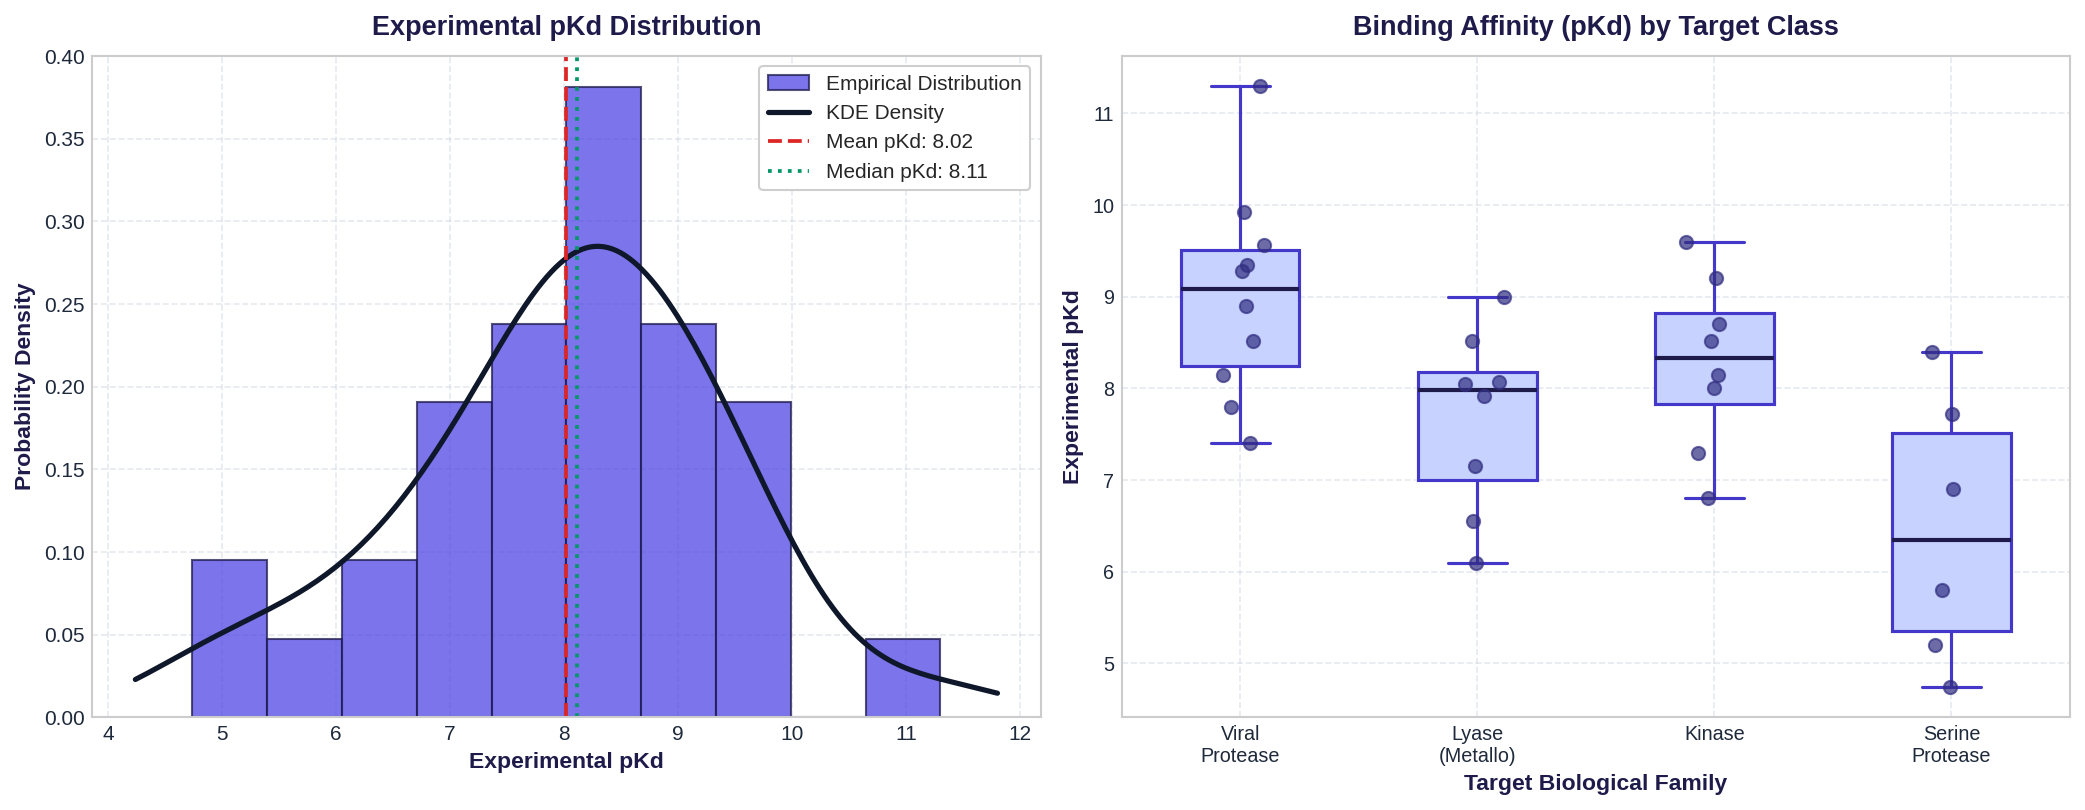

Overall pKd dynamic range: 4.74 to 11.30 (6.56 log orders of magnitude)


In [5]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# Left: Overall pKd distribution with KDE
ax0 = axes[0]
n, bins, patches = ax0.hist(
    affinity_df["pKd"],
    bins=10,
    color="#4f46e5",
    edgecolor="#1e1b4b",
    alpha=0.75,
    density=True,
    label="Empirical Distribution"
)
# Overlay Gaussian KDE
from scipy.stats import gaussian_kde
kde = gaussian_kde(affinity_df["pKd"])
x_grid = np.linspace(affinity_df["pKd"].min() - 0.5, affinity_df["pKd"].max() + 0.5, 200)
ax0.plot(x_grid, kde(x_grid), color="#0f172a", lw=2.5, label="KDE Density")
ax0.axvline(affinity_df["pKd"].mean(), color="#dc2626", ls="--", lw=1.8, label=f"Mean pKd: {affinity_df['pKd'].mean():.2f}")
ax0.axvline(affinity_df["pKd"].median(), color="#059669", ls=":", lw=1.8, label=f"Median pKd: {affinity_df['pKd'].median():.2f}")
ax0.set_title("Experimental pKd Distribution", fontsize=13, fontweight="bold", color="#1e1b4b", pad=10)
ax0.set_xlabel("Experimental pKd", fontsize=11, fontweight="bold", color="#1e1b4b")
ax0.set_ylabel("Probability Density", fontsize=11, fontweight="bold", color="#1e1b4b")
ax0.legend(frameon=True, facecolor="#ffffff", framealpha=0.95)
ax0.tick_params(colors="#1e293b", labelsize=10)
ax0.grid(True, ls="--", alpha=0.5, color="#cbd5e1")

# Right: Boxplot by Target Family
ax1 = axes[1]
families = affinity_df["family"].unique()
family_pkd = [affinity_df[affinity_df["family"] == f]["pKd"].values for f in families]

box = ax1.boxplot(
    family_pkd,
    tick_labels=[f.replace(" ", "\n") for f in families],
    patch_artist=True,
    widths=0.5,
    medianprops=dict(color="#1e1b4b", lw=2),
    boxprops=dict(facecolor="#c7d2fe", edgecolor="#4338ca", lw=1.5),
    whiskerprops=dict(color="#4338ca", lw=1.5),
    capprops=dict(color="#4338ca", lw=1.5),
    flierprops=dict(marker="o", markerfacecolor="#4f46e5", markeredgecolor="#1e1b4b", markersize=6)
)

# Strip plot jitter overlay
for i, f in enumerate(families, start=1):
    vals = affinity_df[affinity_df["family"] == f]["pKd"].values
    jitter = np.random.normal(0, 0.05, size=len(vals))
    ax1.scatter(i + jitter, vals, color="#312e81", alpha=0.7, s=40, zorder=3)

ax1.set_title("Binding Affinity (pKd) by Target Class", fontsize=13, fontweight="bold", color="#1e1b4b", pad=10)
ax1.set_xlabel("Target Biological Family", fontsize=11, fontweight="bold", color="#1e1b4b")
ax1.set_ylabel("Experimental pKd", fontsize=11, fontweight="bold", color="#1e1b4b")
ax1.tick_params(colors="#1e293b", labelsize=9.5)
ax1.grid(True, ls="--", alpha=0.5, color="#cbd5e1")

plt.tight_layout()
plt.show()

print(f"Overall pKd dynamic range: {affinity_df['pKd'].min():.2f} to {affinity_df['pKd'].max():.2f} "
      f"({affinity_df['pKd'].max() - affinity_df['pKd'].min():.2f} log orders of magnitude)")


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
08. Ligand Featurization with DeepChem CircularFingerprint
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Generating 1024-bit Extended Connectivity Molecular Fingerprints (ECFP4)</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Molecular Representation: Circular Fingerprints (ECFP4)
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In accordance with the standard ligand-based workflow, we extract molecular substructure environments using DeepChem's <code>CircularFingerprint(radius=2, size=1024)</code> (equivalent to Extended-Connectivity Fingerprints with diameter 4, ECFP4):
</p>

<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 14px;">
<li><b>Radius 2 (Diameter 4):</b> Encodes circular atom neighborhoods up to two chemical bonds away.</li>
<li><b>1024-bit bitvector:</b> Fixed-length bit representations suitable for tabular regression algorithms.</li>
<li><b>Data Cleaning:</b> Drops any missing SMILES or pKd entries and converts targets to floating-point NumPy arrays.</li>
</ul>
</div>


In [6]:
# Validate and clean the curated dataset.
affinity_df = affinity_df.dropna(
    subset=["smiles", "pKd"]).copy()
affinity_df["pKd"] = pd.to_numeric(
    affinity_df["pKd"],
    errors="coerce",
)
affinity_df = affinity_df.dropna(subset=["pKd"])

# Generate molecular fingerprints.
featurizer = CircularFingerprint(
    radius=2,
    size=1024,
)
X = featurizer.featurize(
    affinity_df["smiles"].tolist())
y = affinity_df["pKd"].to_numpy()

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

# Audit fingerprint sparsity
active_bits_per_mol = np.sum(X, axis=1)
print(f"Active bits per ligand: Mean={np.mean(active_bits_per_mol):.1f}, "
      f"Min={np.min(active_bits_per_mol)}, Max={np.max(active_bits_per_mol)}")


Feature matrix: (32, 1024)
Target vector: (32,)
Active bits per ligand: Mean=44.4, Min=15.0, Max=75.0


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
09. Model Training & Validation Workflow
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Training DummyRegressor Baseline and Machine Learning RandomForestRegressor on Held-Out Test Complexes</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Validation Strategy & Baseline Establishment
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In rigorous regression benchmarking, machine learning models must be compared against a standard baseline:
</p>

<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 14px;">
<li><b>Baseline Model (DummyRegressor):</b> Predicts the mean of the training set affinity (<i>y</i><sub>pred</sub> = <i>y&#772;</i><sub>train</sub>). Any valid predictive model must substantially outperform this reference.</li>
<li><b>Primary Model (RandomForestRegressor):</b> An ensemble of 200 de-correlated decision trees that captures non-linear substructure combinations and interaction terms.</li>
<li><b>Train/Test Split:</b> 75% training complexes (24 complexes) and 25% held-out evaluation complexes (8 complexes) spanning target classes.</li>
</ul>
</div>


In [7]:
from sklearn.model_selection import train_test_split

# Split into 75% train and 25% test sets
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, affinity_df, test_size=0.25, random_state=7, stratify=None
)

print(f"Training set:   {X_train.shape[0]} complexes")
print(f"Evaluation set: {X_test.shape[0]} complexes")

# 1. Baseline Model: DummyRegressor
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)
y_pred_dummy = dummy_reg.predict(X_test)

# 2. Machine Learning Model: RandomForestRegressor
rf_reg = RandomForestRegressor(
    n_estimators=200,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)
rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)

print("\nModel training completed successfully.")


Training set:   24 complexes
Evaluation set: 8 complexes



Model training completed successfully.


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
10. Evaluation Metrics & Parity Diagnostics
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Reporting MAE, RMSE, R2, Pearson Correlation, and Parity/Residual Visualizations</p>
</div>


Evaluation Metrics on Held-Out Test Complexes:


,MAE,RMSE,R2,Pearson_r
DummyRegressor (Mean Baseline),1.207,1.506,-0.029,0.000
RandomForestRegressor (ECFP4),0.803,1.025,0.523,0.823


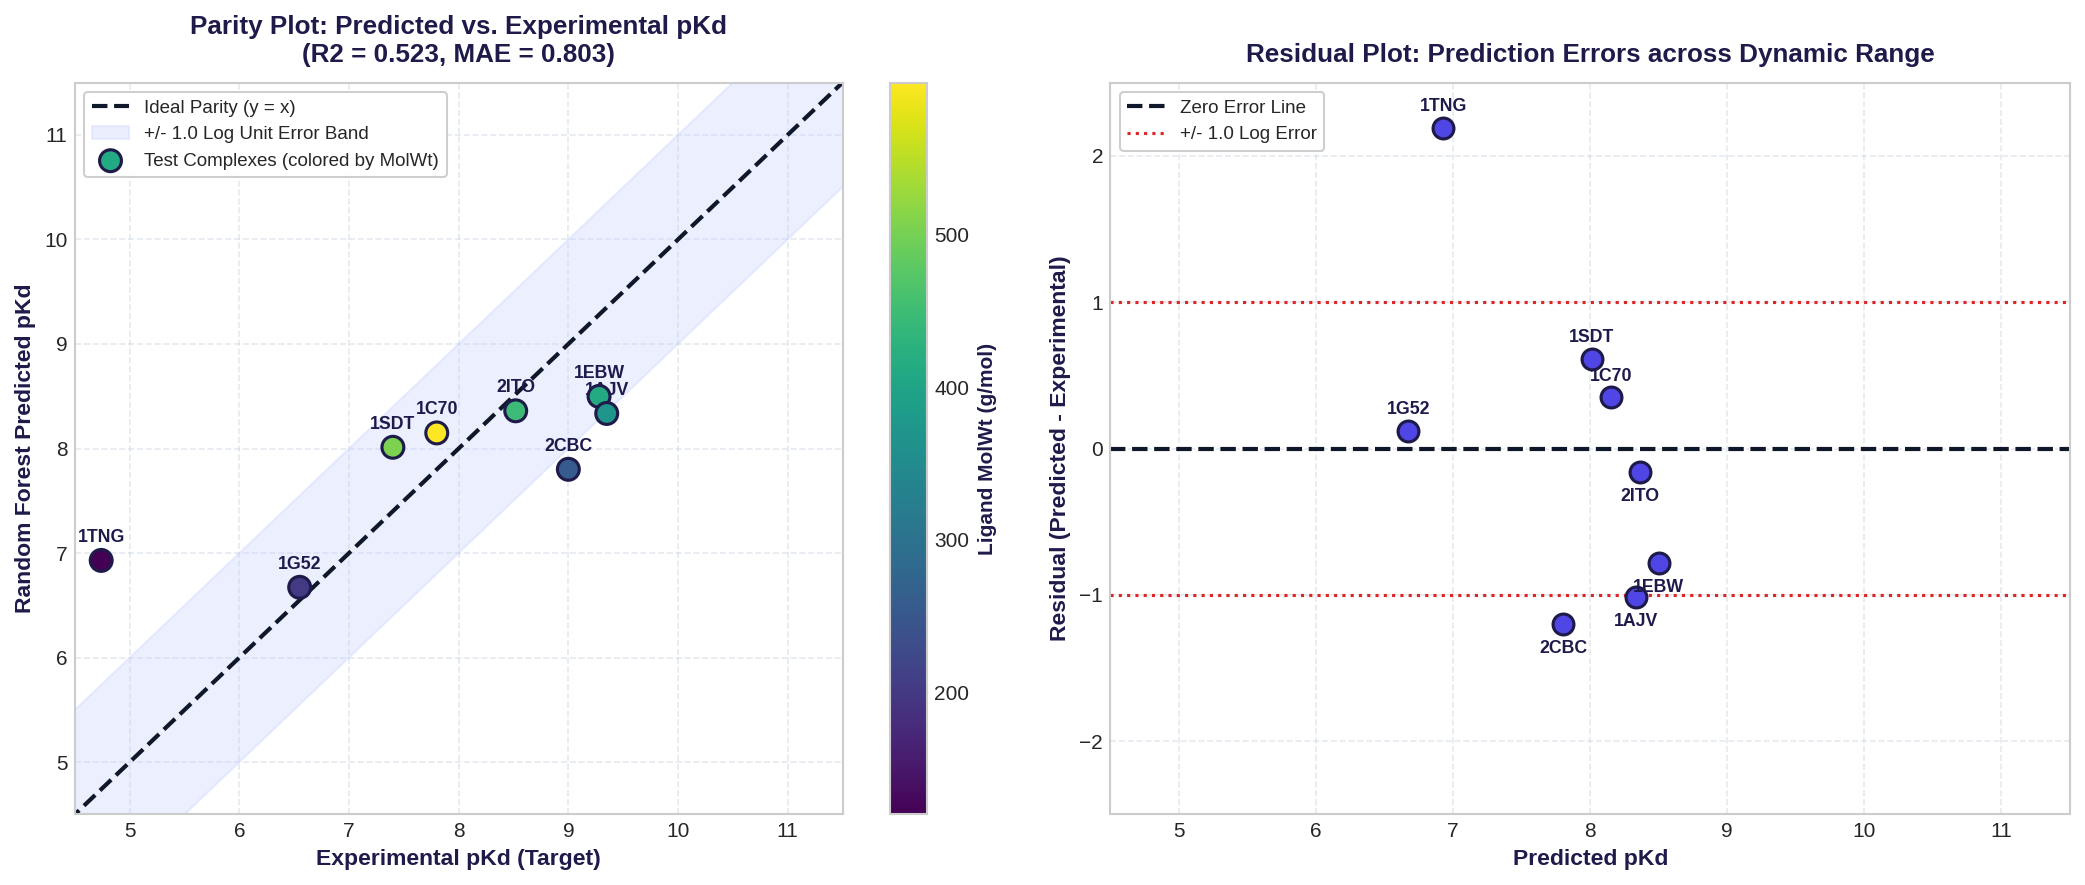

In [8]:
from scipy.stats import pearsonr

# Calculate regression performance metrics
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    p_corr, _ = pearsonr(y_true, y_pred) if len(np.unique(y_pred)) > 1 else (0.0, 1.0)
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "Pearson_r": p_corr}

dummy_metrics = compute_metrics(y_test, y_pred_dummy)
rf_metrics = compute_metrics(y_test, y_pred_rf)

metrics_df = pd.DataFrame([dummy_metrics, rf_metrics], index=["DummyRegressor (Mean Baseline)", "RandomForestRegressor (ECFP4)"])
print("Evaluation Metrics on Held-Out Test Complexes:")
display(metrics_df.round(3))

# Side-by-side diagnostic visualization: Parity Plot & Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

# Panel 1: Parity Plot (Predicted vs Experimental)
ax0 = axes[0]
ax0.plot([4, 12], [4, 12], color="#0f172a", ls="--", lw=2, label="Ideal Parity (y = x)")
ax0.fill_between([4, 12], [3, 11], [5, 13], color="#c7d2fe", alpha=0.35, label="+/- 1.0 Log Unit Error Band")

scatter = ax0.scatter(
    y_test,
    y_pred_rf,
    c=df_test["mol_weight"],
    cmap="viridis",
    s=110,
    edgecolor="#1e1b4b",
    lw=1.5,
    zorder=4,
    label="Test Complexes (colored by MolWt)"
)
cbar = plt.colorbar(scatter, ax=ax0)
cbar.set_label("Ligand MolWt (g/mol)", fontsize=10, color="#1e1b4b", fontweight="bold")

# Annotate points with PDB IDs
for idx, (yt, yp, pdb) in enumerate(zip(y_test, y_pred_rf, df_test["pdb_id"])):
    ax0.annotate(
        pdb,
        (yt, yp),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color="#1e1b4b"
    )

ax0.set_xlim(4.5, 11.5)
ax0.set_ylim(4.5, 11.5)
ax0.set_title(f"Parity Plot: Predicted vs. Experimental pKd\n(R2 = {rf_metrics['R2']:.3f}, MAE = {rf_metrics['MAE']:.3f})",
              fontsize=12.5, fontweight="bold", color="#1e1b4b", pad=10)
ax0.set_xlabel("Experimental pKd (Target)", fontsize=11, fontweight="bold", color="#1e1b4b")
ax0.set_ylabel("Random Forest Predicted pKd", fontsize=11, fontweight="bold", color="#1e1b4b")
ax0.legend(loc="upper left", frameon=True, facecolor="#ffffff", framealpha=0.95, fontsize=9)
ax0.grid(True, ls="--", alpha=0.5, color="#cbd5e1")

# Panel 2: Residual Plot
ax1 = axes[1]
residuals = y_pred_rf - y_test
ax1.axhline(0, color="#0f172a", ls="--", lw=2, label="Zero Error Line")
ax1.axhline(1.0, color="#dc2626", ls=":", lw=1.5, label="+/- 1.0 Log Error")
ax1.axhline(-1.0, color="#dc2626", ls=":", lw=1.5)

ax1.scatter(
    y_pred_rf,
    residuals,
    color="#4f46e5",
    s=100,
    edgecolor="#1e1b4b",
    lw=1.5,
    zorder=3
)

for idx, (yp, res, pdb) in enumerate(zip(y_pred_rf, residuals, df_test["pdb_id"])):
    ax1.annotate(
        pdb,
        (yp, res),
        textcoords="offset points",
        xytext=(0, 8 if res >= 0 else -14),
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color="#1e1b4b"
    )

ax1.set_xlim(4.5, 11.5)
ax1.set_ylim(-2.5, 2.5)
ax1.set_title("Residual Plot: Prediction Errors across Dynamic Range", fontsize=12.5, fontweight="bold", color="#1e1b4b", pad=10)
ax1.set_xlabel("Predicted pKd", fontsize=11, fontweight="bold", color="#1e1b4b")
ax1.set_ylabel("Residual (Predicted - Experimental)", fontsize=11, fontweight="bold", color="#1e1b4b")
ax1.legend(loc="upper left", frameon=True, facecolor="#ffffff", framealpha=0.95, fontsize=9)
ax1.grid(True, ls="--", alpha=0.5, color="#cbd5e1")

plt.tight_layout()
plt.show()


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
11. Research Interpretation: Generalization & 'Target Blindness'
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">Why Ligand-Only Models Cannot Distinguish Different Protein Pockets and the Need for Structure-Aware Architectures</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
The Fundamental Limitation: "Target Blindness"
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
The most critical research finding when applying ligand fingerprints (ECFP, MACCS, RDKit descriptors) to protein–ligand binding datasets is <b>target blindness</b>:
</p>

<div style="background: #fff1f2; border: 1px solid #fecdd3; border-left: 5px solid #e11d48; border-radius: 8px; padding: 14px 18px; margin: 14px 0;">
<div style="font-weight: 700; color: #9f1239; font-size: 14px; margin-bottom: 6px;">The Mathematical Reality of Ligand-Only Scoring</div>
<div style="font-size: 13.5px; color: #881337; line-height: 1.6;">
A ligand-only model is a function <i>f</i>: X<sub>ligand</sub> &rarr; &reals;. It possesses <b>zero inputs representing the protein target</b>. Consequently:
<div style="text-align: center; font-family: monospace; font-size: 14px; font-weight: 700; color: #9f1239; margin: 10px 0;">
<i>f</i>(Ligand<sub>A</sub>, HIV-1 Protease) &nbsp;&equiv;&nbsp; <i>f</i>(Ligand<sub>A</sub>, Carbonic Anhydrase) &nbsp;&equiv;&nbsp; <i>f</i>(Ligand<sub>A</sub>, Trypsin)
</div>
If the same compound is evaluated against ten entirely different biological receptors, a ligand-only model outputs the exact same numerical prediction for all ten targets!
</div>
</div>

<h4 style="margin: 18px 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Demonstrating Target Blindness Experimentally
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 12px;">
In the code cell below, we prove this limitation directly by querying our trained Random Forest model with known therapeutic ligands across hypothetical alternative target pockets.
</p>
</div>


In [ ]:
# Empirical Proof of Target Blindness
sample_ligands = [
    {"name": "Acetazolamide", "smiles": "CC(=O)Nc1nnc(s1)S(=O)(=O)N", "true_target": "Carbonic Anhydrase II", "true_pKd": 7.92},
    {"name": "Benzamidine", "smiles": "NC(=N)c1ccccc1", "true_target": "Trypsin", "true_pKd": 4.74},
    {"name": "Erlotinib", "smiles": "COCCOC1=C(OCCOC)C=C2C(=C1)N=CN=C2NC3=CC=CC(=C3)C#C", "true_target": "EGFR Kinase", "true_pKd": 8.70}
]

hypothetical_targets = ["HIV-1 Protease", "Carbonic Anhydrase II", "EGFR Kinase", "Trypsin", "Streptavidin"]

blindness_records = []
for lig in sample_ligands:
    fp = featurizer.featurize([lig["smiles"]])
    pred = rf_reg.predict(fp)[0]
    for target in hypothetical_targets:
        blindness_records.append({
            "Ligand": lig["name"],
            "True Target": lig["true_target"],
            "Queried Target Pocket": target,
            "Experimental pKd on True Target": lig["true_pKd"],
            "Model Predicted pKd": round(pred, 2),
            "Pocket Aware?": "NO (Target Blind)"
        })

blindness_df = pd.DataFrame(blindness_records)
print("Target Blindness Audit Table (Same Ligand Queried Across Different Pockets):")
display(blindness_df.head(10))

Target Blindness Audit Table (Same Ligand Queried Across Different Pockets):


,Ligand,True Target,Queried Target Pocket,Experimental pKd on True Target,Model Predicted pKd,Pocket Aware?
0,Acetazolamide,Carbonic Anhydrase II,HIV-1 Protease,7.92,7.73,NO (Target Blind)
1,Acetazolamide,Carbonic Anhydrase II,Carbonic Anhydrase II,7.92,7.73,NO (Target Blind)
2,Acetazolamide,Carbonic Anhydrase II,EGFR Kinase,7.92,7.73,NO (Target Blind)
3,Acetazolamide,Carbonic Anhydrase II,Trypsin,7.92,7.73,NO (Target Blind)
4,Acetazolamide,Carbonic Anhydrase II,Streptavidin,7.92,7.73,NO (Target Blind)
5,Benzamidine,Trypsin,HIV-1 Protease,4.74,6.93,NO (Target Blind)
6,Benzamidine,Trypsin,Carbonic Anhydrase II,4.74,6.93,NO (Target Blind)
7,Benzamidine,Trypsin,EGFR Kinase,4.74,6.93,NO (Target Blind)
8,Benzamidine,Trypsin,Trypsin,4.74,6.93,NO (Target Blind)
9,Benzamidine,Trypsin,Streptavidin,4.74,6.93,NO (Target Blind)


<div style="background: linear-gradient(135deg, #f8fafc, #eef2ff);
color: #1e1b4b;
border-radius: 12px;
margin: 20px auto;
padding: 20px 24px;
border: 1px solid #c7d2fe;
border-left: 6px solid #4f46e5;
max-width: 1300px;
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
line-height: 1.6;
box-shadow: 0 4px 15px rgba(0,0,0,0.05);">
<h2 style="margin: 0; text-align: center; color: #1e1b4b; font-size: 21px; font-weight: 700; letter-spacing: -0.01em;">
12. Pathways to Structure-Aware Affinity Modeling & Next Steps
</h2>
<p style="margin: 6px 0 0 0; text-align: center; color: #4338ca; font-size: 14px; font-weight: 500;">From 2D Ligand Models to Protein Sequences, Pocket Embeddings, and 3D Complex Graph Convolutions</p>
</div>

<div style="background: linear-gradient(135deg, #ffffff 0%, #f8faff 100%);
border: 1px solid #cbd5e1;
border-left: 6px solid #4f46e5;
border-radius: 14px;
padding: 24px 28px;
margin: 20px 0;
box-shadow: 0 4px 20px rgba(0,0,0,0.06);
font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
color: #1e293b;
line-height: 1.65;">
<h4 style="margin: 0 0 10px 0; color: #1e1b4b; font-size: 16px; font-weight: 700;">
Taxonomy of Protein–Ligand Affinity Architectures
</h4>
<p style="font-size: 14px; color: #334155; margin-bottom: 14px;">
To transcend ligand-only limitations, modern computational drug discovery employs three tiers of target-aware representations:
</p>

<table style="width: 100%; border-collapse: collapse; font-size: 13.5px; color: #334155; margin-top: 8px;">
<thead>
<tr style="background-color: #f1f5f9; border-bottom: 2px solid #cbd5e1;">
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Tier</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Architecture Paradigm</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Input Representations</th>
<th style="padding: 10px; text-align: left; color: #1e1b4b;">Key DeepChem / ML Tools</th>
</tr>
</thead>
<tbody>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Tier 1: Ligand-Only</td>
<td style="padding: 9px;">ECFP / Graph Neural Net on small molecule alone.</td>
<td style="padding: 9px;">SMILES, Morgan fingerprints, 2D molecular graphs.</td>
<td style="padding: 9px;"><code>CircularFingerprint</code>, <code>GraphConvModel</code>, RF. Ideal for single-target SAR series.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Tier 2: Sequence-Aware (DTI / CPI)</td>
<td style="padding: 9px;">Dual-branch neural networks fusing ligand graph with target sequence embeddings.</td>
<td style="padding: 9px;">Ligand graph + Target FASTA amino acid sequence (ESM-2, ProtBERT, 1D CNN).</td>
<td style="padding: 9px;">GraphDTA, DeepAffinity, TransformerCPI. Enables zero-shot generalization across targets.</td>
</tr>
<tr style="border-bottom: 1px solid #e2e8f0;">
<td style="padding: 9px; font-weight: 600; color: #1e1b4b;">Tier 3: Structure-Aware (3D Complex)</td>
<td style="padding: 9px;">3D voxel CNNs or Equivariant Graph Neural Networks (EGNNs) modeling atomic coordinates.</td>
<td style="padding: 9px;">Co-crystallized 3D complex (<i>x</i>, <i>y</i>, <i>z</i>) coordinates, distance matrices, pocket surface meshes.</td>
<td style="padding: 9px;"><code>AtomicConvModel</code>, <code>RdkitGridFeaturizer</code>, Pafnucy, SchNet, TorchMD-NET.</td>
</tr>
</tbody>
</table>

<h4 style="margin: 18px 0 8px 0; color: #1e1b4b; font-size: 15px; font-weight: 700;">
Looking Ahead in the DeepChem Curriculum
</h4>
<ul style="font-size: 13.5px; color: #334155; margin-left: 20px; line-height: 1.7; margin-bottom: 14px;">
<li><b>Notebook 09: AI Drug Discovery Pipeline:</b> Integrating target identification, hit finding, affinity filtering, and ADMET toxicity screening into an automated end-to-end campaign.</li>
<li><b>Notebook 10: Model Evaluation & Interpretability:</b> Exploring SHAP, Integrated Gradients, and scaffold-aware uncertainty estimation for production deployment.</li>
</ul>
</div>
